<a href="https://colab.research.google.com/github/giraseniraj21-cyber/ML/blob/main/Practical_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*   Student Name : Girase Niraj Jaypalsing
*   Div : A
*   Practical Batch : A-2
*   Roll No.: 41
*   Date : 29/10/2026
*   Practical No.: 07
*   Practical Name : Apply K-Means and visualize Clusters. Use Silhouette Score and Elbow method to tune K.

**1. Data Loading**

In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams[ 'figure.figsize'] = (6, 5) #DefauLt fig size
plt.rcParams[ 'figure.dpi'] = 150 #DefauLt fig resolution
sns.set_style( 'darkgrid') #DefauLt diagram theme

In [ ]:
df = pd.read_csv('Mall_Customers.csv')
df. head ( )

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**2. Exploratory Data Analysis & Visualization**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
# Drop the unnecessary columns
df.drop(['CustomerID', 'Gender', 'Age'], axis=1, inplace=True)
df.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


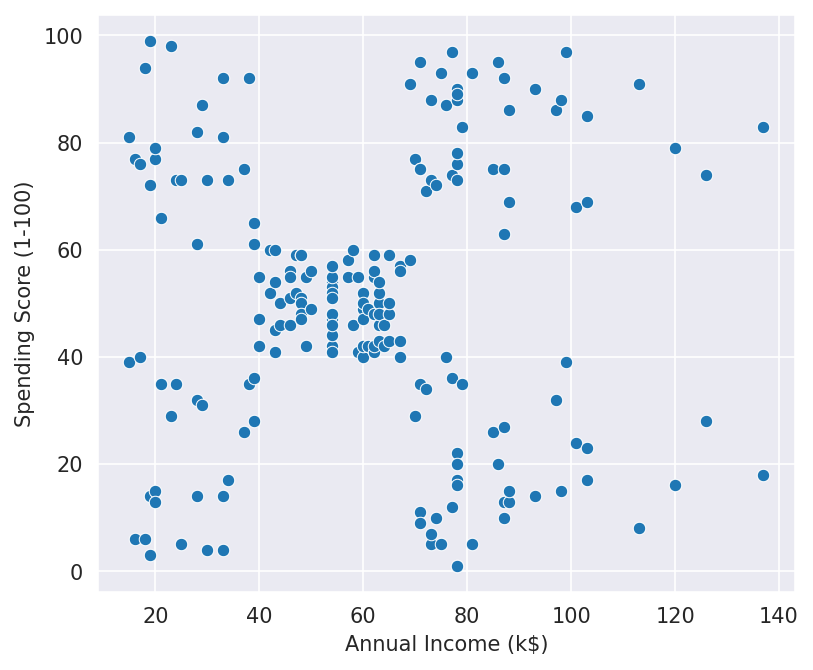

In [ ]:
# Data visualization
sns.scatterplot(x= df['Annual Income (k$)'], y = df['Spending Score (1-100)'])
plt.show()

**3. Data Preprocessing**

In [ ]:
# Standardization
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()

x = sc.fit_transform(df)
x[:10]

array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

**4. Model Development (K-Means Clustering)**

In [ ]:
from sklearn.cluster import KMeans
km = KMeans()   # default 8 Cluster
yp = km.fit_predict(x)
yp

array([4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 5, 1, 5, 5,
       4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5,
       5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 0, 5, 5, 0, 5, 5, 5, 5, 5,
       5, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 0, 2, 3, 2, 3, 2,
       0, 2, 3, 2, 3, 2, 3, 2, 3, 2, 0, 2, 3, 2, 0, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 3, 2, 0, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2, 3, 2,
       3, 2, 3, 2, 6, 2, 6, 2, 6, 2, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7, 6, 7,
       6, 7], dtype=int32)

In [ ]:
len(yp)

200

In [ ]:
# cluster center
km.cluster_centers_

array([[ 0.12948524, -0.15473165],
       [-1.35366972,  1.15873115],
       [ 0.75632724,  1.27092084],
       [ 0.7489536 , -1.45651437],
       [-1.35185213, -1.19089759],
       [-0.50061327,  0.04054696],
       [ 1.87564575, -1.09476801],
       [ 2.06703817,  1.0958772 ]])

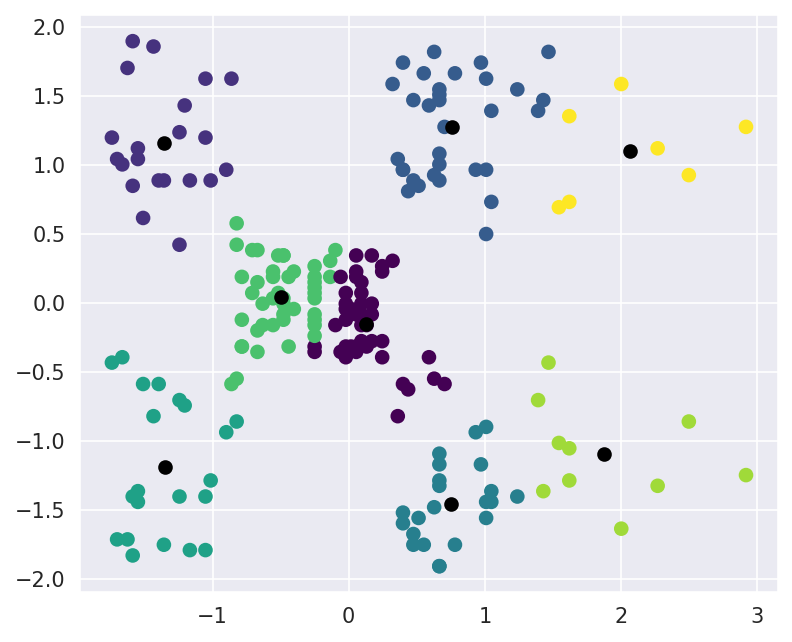

In [ ]:
#Visualize the clusters - Scatter plot with centroid of each cluster
plt.scatter(x[:,0],x[:,1], c = yp, cmap='viridis')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], c='black')
plt.show()

In [ ]:
km.inertia_

37.61591613378229

**Elbow graph / Elbow Curve**
*   Elbow curve is the plot between Kvalues and wcss

In [ ]:
# WCC (Within-Cluster sum of squares)
wcss = []

for i in range(1, 20) :
  km = KMeans(n_clusters=i)
  km.fit(x)
  wcss.append(km.inertia_)

In [ ]:
wcss

[399.99999999999994,
 272.8564265524899,
 157.70400815035939,
 109.22822707921345,
 98.80769272556533,
 55.057348270385965,
 44.86628627232252,
 37.31912287833882,
 40.739114063499,
 32.65658176281903,
 25.905865152509044,
 24.505954235742475,
 21.162943656049176,
 20.41777549626932,
 17.766680838372015,
 17.85341478834043,
 16.25429740339193,
 15.99655502381599,
 13.0782862697024]

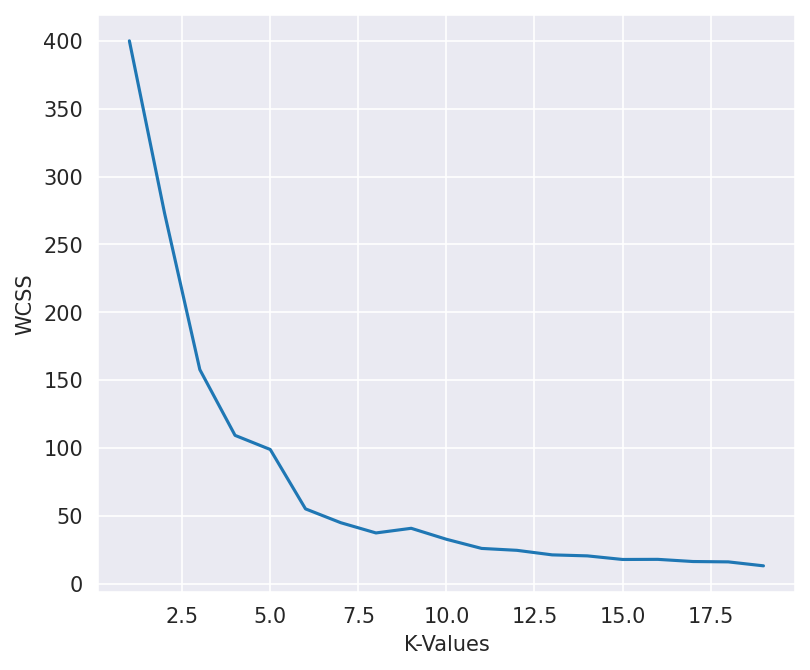

In [ ]:
plt.plot(range(1, 20),wcss)
plt.xlabel('K-Values')
plt.ylabel('WCSS')
plt.show()

**5. Model Evaluation & Optimal K Selection**

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_score(x,yp)

np.float64(0.4579481342797775)

**Optimal K Determination & Final K-Means Model**

K =2, Silhouette Score = 0.321
K =3, Silhouette Score = 0.467
K =4, Silhouette Score = 0.494
K =5, Silhouette Score = 0.555
K =6, Silhouette Score = 0.540
K =7, Silhouette Score = 0.528
K =8, Silhouette Score = 0.455
K =9, Silhouette Score = 0.457
K =10, Silhouette Score = 0.443


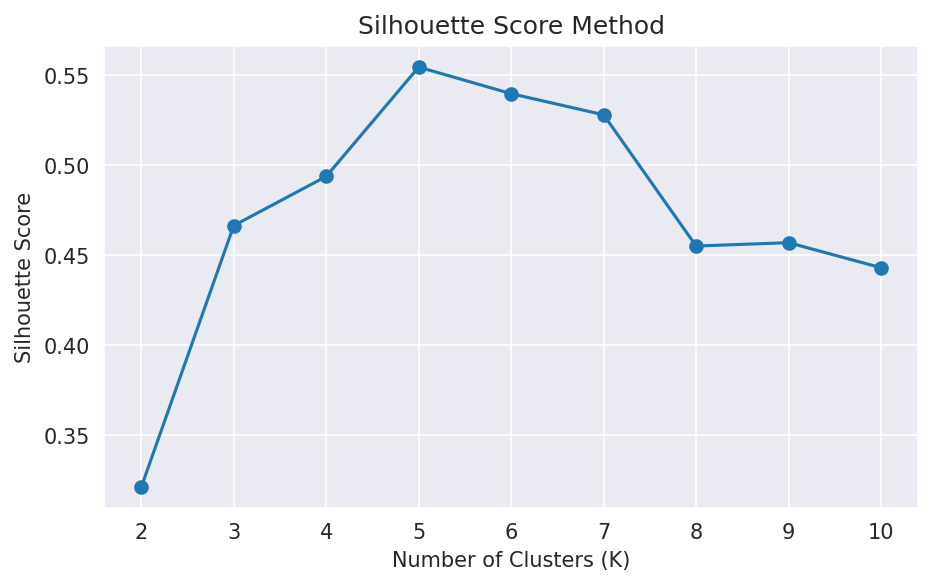

In [ ]:
# Step 5 : Silhouette Score Analysis
from sklearn.metrics import silhouette_score
silhouette_scores = []

for k in range(2, 11) :
  kmeans = KMeans(
      n_clusters=k,
      random_state=42,
      n_init=10
      )
  labels = kmeans.fit_predict(x)
  score = silhouette_score(x, labels)
  silhouette_scores.append(score)
  print(f"K ={k}, Silhouette Score = {score:.3f}")

# Visualization Silhouette Scores
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()